# Exploratory Data Analysis: Demand Forecasting

This notebook explores the **cleaned, windowed data** cached in `data/processed/`
by `src/pipeline.py`. Run the pipeline at least once first (see README) so that
`{dataset}_cleaned_long.parquet` exists.

Covers:
1. Overview & missingness
2. Demand distribution (why we use quantile regression, not Gaussian assumptions)
3. Time series trends per SKU
4. Day-of-week / seasonality patterns
5. Autocorrelation (ACF/PACF) -- motivates SARIMA's seasonal order
6. Promo / price effect on demand
7. Intermittency (zero-demand days) -- motivates quantile regression over MSE


In [2]:
import sys
sys.path.append('..')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

from src.preprocessing import load_processed_long_df, DATE_COL, SKU_COL, TARGET_COL

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (11, 4)

DATASET_NAME = 'rossmann'  # change to 'm5' to explore the other dataset
from pathlib import Path

df = load_processed_long_df(DATASET_NAME, processed_dir=Path('../data/processed'))
df.head()

,date,sku_id,units_sold,day_of_week,promo,competition_distance,promo2,store_type_code,assortment_code,week_of_year
0,2013-01-02,1,5530.0,2,0.0,1270.0,0.0,2.0,0.0,1
1,2013-01-03,1,4327.0,3,0.0,1270.0,0.0,2.0,0.0,1
2,2013-01-04,1,4486.0,4,0.0,1270.0,0.0,2.0,0.0,1
3,2013-01-05,1,4997.0,5,0.0,1270.0,0.0,2.0,0.0,1
4,2013-01-06,1,0.0,6,0.0,1270.0,0.0,2.0,0.0,1


## 1. Overview & Missingness

In [3]:
print('Shape:', df.shape)
print('Date range:', df[DATE_COL].min(), '->', df[DATE_COL].max())
print('Number of series (SKUs/stores):', df[SKU_COL].nunique())
df.describe()

Shape: (1048712, 10)
Date range: 2013-01-01 00:00:00 -> 2015-07-31 00:00:00
Number of series (SKUs/stores): 1115


,date,sku_id,units_sold,day_of_week,promo,competition_distance,promo2,store_type_code,assortment_code,week_of_year
count,1048712,1.048712e+06,1.048712e+06,1.048712e+06,1.048712e+06,1.048712e+06,1.048712e+06,1.048712e+06,1.048712e+06,1.048712e+06
mean,2014-04-17 03:44:06.839934,5.580051e+02,5.600375e+03,2.999970e+00,4.013142e-01,5.595685e+03,5.123285e-01,1.216704e+00,9.281385e-01,2.412814e+01
min,2013-01-01 00:00:00,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,2.000000e+01,0.000000e+00,0.000000e+00,0.000000e+00,1.000000e+00
25%,2013-08-25 00:00:00,2.790000e+02,3.428000e+03,1.000000e+00,0.000000e+00,7.200000e+02,0.000000e+00,0.000000e+00,0.000000e+00,1.200000e+01
50%,2014-04-17 00:00:00,5.580000e+02,5.634000e+03,3.000000e+00,0.000000e+00,2.330000e+03,1.000000e+00,0.000000e+00,0.000000e+00,2.300000e+01
75%,2014-12-08 00:00:00,8.370000e+02,7.773000e+03,5.000000e+00,1.000000e+00,6.910000e+03,1.000000e+00,3.000000e+00,2.000000e+00,3.600000e+01
max,2015-07-31 00:00:00,1.115000e+03,4.155100e+04,6.000000e+00,1.000000e+00,7.586000e+04,1.000000e+00,3.000000e+00,2.000000e+00,5.200000e+01
std,NaN,3.218087e+02,3.917657e+03,1.997349e+00,4.901646e-01,8.476876e+03,4.998482e-01,1.368996e+00,9.933542e-01,1.452862e+01


In [4]:
# Missingness check -- should be ~0 after fill_missing() in preprocessing.py,
# this cell exists to VERIFY that, not to fix anything.
missing = df.isna().sum()
missing = missing[missing > 0]
if len(missing) == 0:
    print('No missing values remain -- fill_missing() handled it correctly.')
else:
    print(missing)

No missing values remain -- fill_missing() handled it correctly.


## 2. Demand Distribution

This is the plot that justifies using **quantile regression instead of assuming
a Gaussian (Normal) error distribution**. Retail demand is typically right-skewed
and can have a spike at zero (intermittent demand) -- a Gaussian assumption
(as classical MSE-trained models implicitly make) would badly misrepresent this.

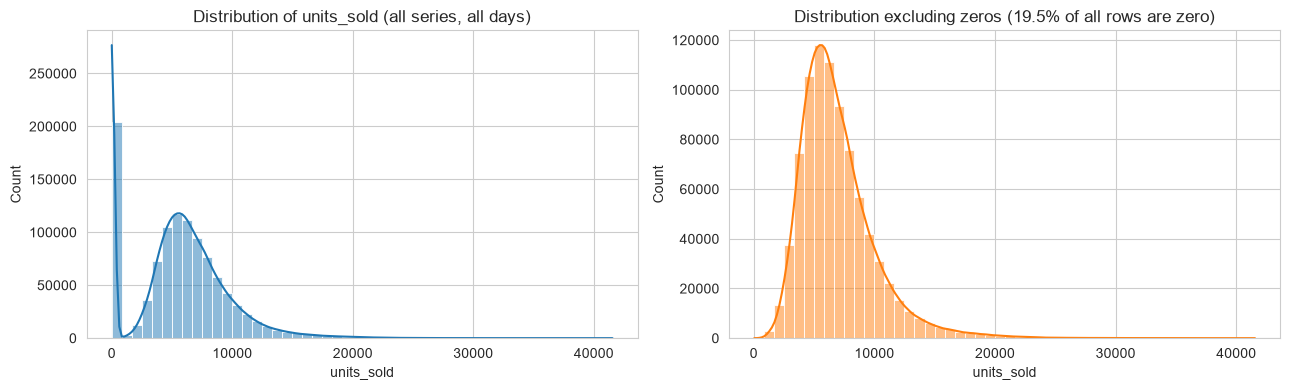

Skewness: 0.63  (0 = symmetric like a Gaussian; this is not 0)
Fraction of zero-demand days: 19.5%


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

sns.histplot(df[TARGET_COL], bins=50, kde=True, ax=axes[0])
axes[0].set_title(f'Distribution of {TARGET_COL} (all series, all days)')
axes[0].set_xlabel(TARGET_COL)

zero_frac = (df[TARGET_COL] == 0).mean()
sns.histplot(df[TARGET_COL][df[TARGET_COL] > 0], bins=50, kde=True, ax=axes[1], color='tab:orange')
axes[1].set_title(f'Distribution excluding zeros ({zero_frac:.1%} of all rows are zero)')
axes[1].set_xlabel(TARGET_COL)

plt.tight_layout()
plt.savefig('../reports/figures/demand_distribution.png', dpi=150)
plt.show()

print(f'Skewness: {df[TARGET_COL].skew():.2f}  (0 = symmetric like a Gaussian; this is not 0)')
print(f'Fraction of zero-demand days: {zero_frac:.1%}')

## 3. Time Series Trends (per SKU)

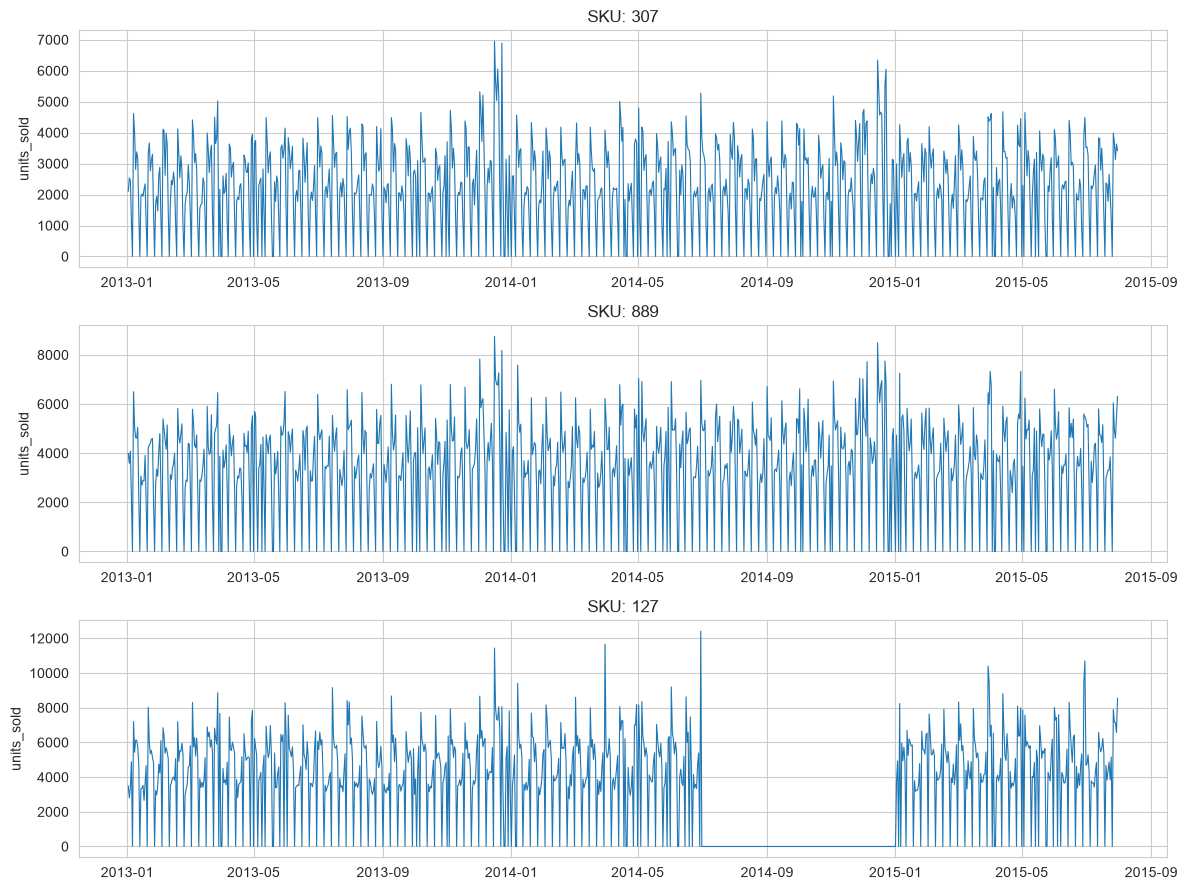

In [6]:
sample_skus = df[SKU_COL].drop_duplicates().sample(min(3, df[SKU_COL].nunique()), random_state=1)

fig, axes = plt.subplots(len(sample_skus), 1, figsize=(12, 3 * len(sample_skus)), sharex=False)
if len(sample_skus) == 1:
    axes = [axes]

for ax, sku in zip(axes, sample_skus):
    series = df[df[SKU_COL] == sku].sort_values(DATE_COL)
    ax.plot(series[DATE_COL], series[TARGET_COL], linewidth=0.8)
    ax.set_title(f'SKU: {sku}')
    ax.set_ylabel(TARGET_COL)

plt.tight_layout()
plt.savefig('../reports/figures/sample_series_trends.png', dpi=150)
plt.show()

## 4. Day-of-Week Seasonality

If demand clearly depends on day-of-week, that justifies SARIMA's seasonal
order (period=7) in `src/baseline_sarima.py`, and confirms the LSTM should be
able to learn this pattern from the raw sequence.

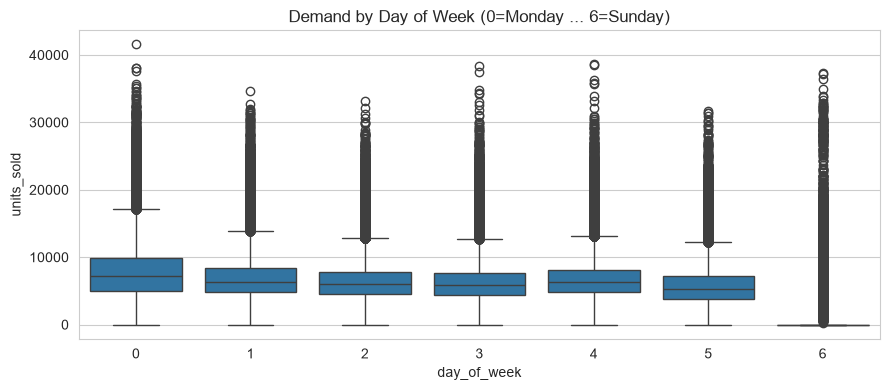

Mean demand by day of week:
day_of_week
0    7568.137916
1    6832.170079
2    6347.461335
3    6056.429524
4    6517.443826
5    5667.167112
6     197.884202
Name: units_sold, dtype: float64


In [7]:
plt.figure(figsize=(9, 4))
sns.boxplot(data=df, x='day_of_week', y=TARGET_COL)
plt.title('Demand by Day of Week (0=Monday ... 6=Sunday)')
plt.tight_layout()
plt.savefig('../reports/figures/day_of_week_seasonality.png', dpi=150)
plt.show()

dow_means = df.groupby('day_of_week')[TARGET_COL].mean()
print('Mean demand by day of week:')
print(dow_means)

## 5. Autocorrelation (ACF / PACF)

These plots directly justify the `seasonal_order=(1,1,1,7)` choice in
`src/baseline_sarima.py` -- a spike at lag 7 in the ACF is exactly what
weekly seasonality looks like statistically, not just visually.

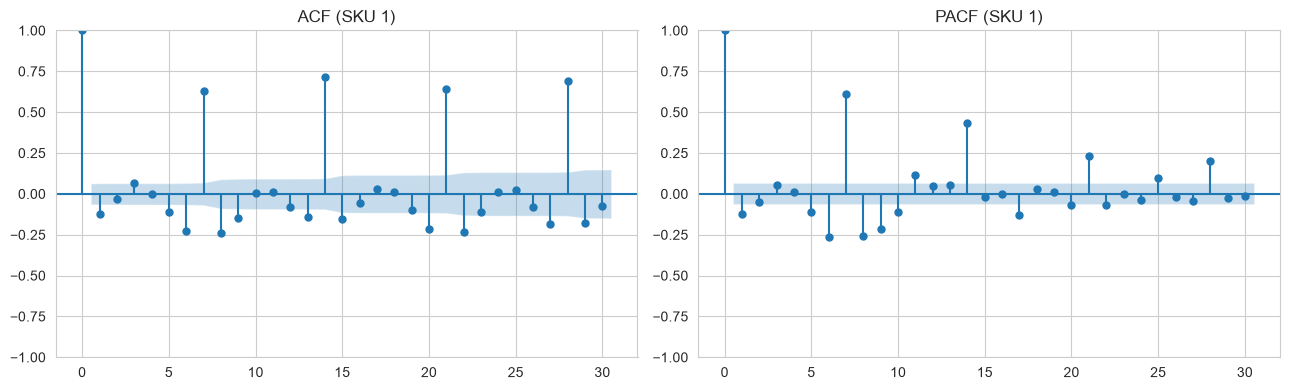

In [8]:
example_sku = df[SKU_COL].drop_duplicates().iloc[0]
example_series = df[df[SKU_COL] == example_sku].sort_values(DATE_COL)[TARGET_COL].values

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
plot_acf(example_series, lags=30, ax=axes[0])
axes[0].set_title(f'ACF (SKU {example_sku})')
plot_pacf(example_series, lags=30, ax=axes[1], method='ywm')
axes[1].set_title(f'PACF (SKU {example_sku})')
plt.tight_layout()
plt.savefig('../reports/figures/acf_pacf.png', dpi=150)
plt.show()

## 6. Promo / Price Effect on Demand

Checks whether the extra feature channels (promo for Rossmann, sell_price for M5)
actually carry a visible relationship with demand -- if they don't, that's worth
knowing before trusting the DL model to use them well.

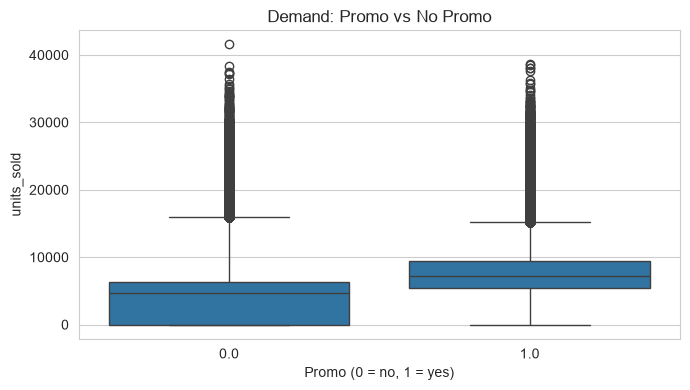

promo
0.0    4415.033451
1.0    7368.683600
Name: units_sold, dtype: float64


In [9]:
if 'promo' in df.columns:
    plt.figure(figsize=(7, 4))
    sns.boxplot(data=df, x='promo', y=TARGET_COL)
    plt.title('Demand: Promo vs No Promo')
    plt.xlabel('Promo (0 = no, 1 = yes)')
    plt.tight_layout()
    plt.savefig('../reports/figures/promo_effect.png', dpi=150)
    plt.show()
    print(df.groupby('promo')[TARGET_COL].mean())

elif 'sell_price' in df.columns:
    plt.figure(figsize=(7, 5))
    sample = df.sample(min(5000, len(df)), random_state=1)
    sns.scatterplot(data=sample, x='sell_price', y=TARGET_COL, alpha=0.3, s=15)
    plt.title('Demand vs Sell Price (sampled points)')
    plt.tight_layout()
    plt.savefig('../reports/figures/price_effect.png', dpi=150)
    plt.show()
    print('Correlation (price, demand):', df['sell_price'].corr(df[TARGET_COL]))

else:
    print('No promo/price column found for this dataset.')

## 7. Intermittency Check (Zero-Demand Days)

Confirms how "spiky"/intermittent the demand is per series -- the more
intermittent, the stronger the case for quantile regression (which naturally
handles a probability mass at zero) over a Gaussian-assumption model.

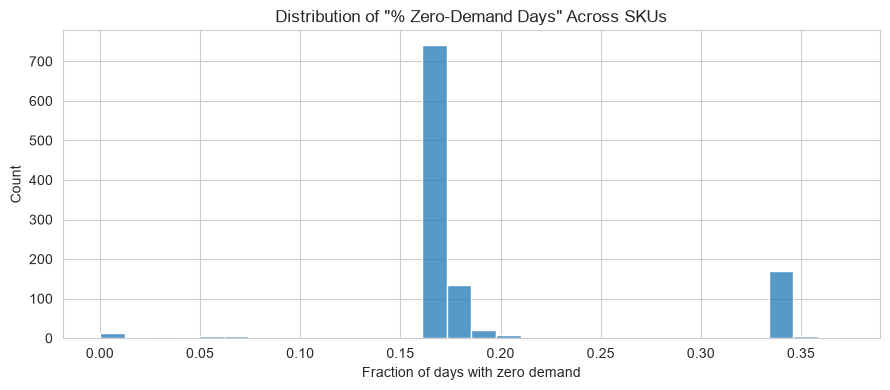

Median zero-demand fraction across SKUs: 17.2%
Most intermittent SKU: 644 (37.1% zero days)


In [10]:
zero_frac_per_sku = df.groupby(SKU_COL)[TARGET_COL].apply(lambda s: (s == 0).mean())

plt.figure(figsize=(9, 4))
sns.histplot(zero_frac_per_sku, bins=30)
plt.title('Distribution of "% Zero-Demand Days" Across SKUs')
plt.xlabel('Fraction of days with zero demand')
plt.tight_layout()
plt.savefig('../reports/figures/zero_demand_fraction.png', dpi=150)
plt.show()

print(f'Median zero-demand fraction across SKUs: {zero_frac_per_sku.median():.1%}')
print(f'Most intermittent SKU: {zero_frac_per_sku.idxmax()} ({zero_frac_per_sku.max():.1%} zero days)')

## Summary

- If demand is right-skewed with a meaningful zero-mass -> supports the
  project's choice of **quantile regression over MSE/Gaussian assumptions**.
- If ACF shows a clear spike at lag 7 -> supports SARIMA's `seasonal_order=(...,7)`.
- If promo/price show a visible relationship with demand -> supports keeping
  them as extra input channels (already wired into `src/preprocessing.py`'s
  `feature_cols`).

All figures are saved to `reports/figures/` for reuse in a report or slide deck.